# Binary Classification

## IMDB dataset

Je gaat werken met de IMDB-dataset: een verzameling van 50.000 sterk gepolariseerde recensies van de Internet Movie Database. Ze zijn verdeeld in 25.000 recensies voor training en 25.000 recensies voor testen, waarbij elke set bestaat uit 50% negatieve en 50% positieve recensies. Net als de MNIST-dataset, wordt de IMDB-dataset meegeleverd met Keras. De dataset is al voorbereid: de recensies (reeksen van woorden) zijn omgezet in reeksen van gehele getallen, waarbij elk geheel getal staat voor een specifiek woord in een woordenboek. Dit stelt ons in staat om ons te concentreren op het bouwen, trainen en evalueren van modellen. De volgende code zal de dataset laden (wanneer je het voor de eerste keer uitvoert, zal ongeveer 80 MB aan gegevens worden gedownload naar je machine).

In [1]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import imdb
from tensorflow.keras.utils import to_categorical

import matplotlib.pyplot as plt

In [2]:
# inladen dataset
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(
num_words=10000)

Het argument num_words=10000 betekent dat je alleen de top 10.000 meest voorkomende woorden in de trainingsdata behoudt. Zeldzame woorden worden verwijderd. Dit stelt ons in staat om te werken met vectorgegevens van een beheersbare grootte. Als we deze limiet niet zouden instellen, zouden we werken met 88.585 unieke woorden in de trainingsdata, wat onnodig groot is. Veel van deze woorden komen slechts in één voorbeeld voor en kunnen daarom niet zinvol worden gebruikt voor classificatie. De variabelen train_data en test_data zijn lijsten van recensies; elke recensie is een lijst van woordindices (die een reeks woorden coderen). train_labels en test_labels zijn lijsten van 0'en en 1'en, waarbij 0 staat voor negatief en 1 voor positief.








In [3]:
max([max(sequence) for sequence in train_data])

9999

In [4]:
# decoderen van een review:
word_index = imdb.get_word_index()

reverse_word_index = dict(
    [(value, key) for (key, value) in word_index.items()])

decoded_review = " ".join([reverse_word_index.get(i - 3, "?") for i in train_data[0]])

1641221/1641221 [==============================] - 1s 0us/step


Dit decodeert de recensie. Merk op dat de indices met 3 verschoven zijn omdat 0, 1 en 2 gereserveerde indices zijn voor respectievelijk "padding" (opvulling), "start of sequence" en "unknown".

In [5]:
decoded_review

"? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also ? to the two little boy's that played the ? of norman and paul they were just brilliant children are often left out of the ? list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done don't you th

### Voorbereiden van de data

In [6]:
### Voorbereiden van de data: encoderen van de integer sequences via multi-hot encoding

import numpy as np
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        for j in sequence:
            results[i, j] = 1.
    return results
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

In [7]:
x_train[0]

array([0., 1., 1., ..., 0., 0., 0.])

In [8]:
len(x_train[0])

10000

We hebben dus een array met de 10000 woorden waarbij enkel de in de review voorkomende woorden 1 zijn en de rest 0.

In [9]:
# labels omzetten naar vectoren
y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")

In [10]:
## Bouwen van het model

model = keras.Sequential([
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [11]:
# Compilen van het model

model.compile(optimizer="rmsprop",
              loss="binary_crossentropy",
              metrics=["accuracy"])

In [12]:
# Validation set afzonderen

x_val = x_train[:10000]
partial_x_train = x_train[10000:]
y_val = y_train[:10000]
partial_y_train = y_train[10000:]

In [13]:
# Trainen van het model

history = model.fit(partial_x_train,
                    partial_y_train,
                    epochs=20,
                    batch_size=512,
                    validation_data=(x_val, y_val))

Epoch 1/20
30/30 [==============================] - 1s 22ms/step - loss: 0.5706 - accuracy: 0.7441 - val_loss: 0.4462 - val_accuracy: 0.8560
Epoch 2/20
30/30 [==============================] - 0s 9ms/step - loss: 0.3667 - accuracy: 0.8873 - val_loss: 0.3412 - val_accuracy: 0.8792
Epoch 3/20
30/30 [==============================] - 0s 9ms/step - loss: 0.2712 - accuracy: 0.9148 - val_loss: 0.3062 - val_accuracy: 0.8811
Epoch 4/20
30/30 [==============================] - 0s 9ms/step - loss: 0.2179 - accuracy: 0.9283 - val_loss: 0.2864 - val_accuracy: 0.8863
Epoch 5/20
30/30 [==============================] - 0s 9ms/step - loss: 0.1806 - accuracy: 0.9412 - val_loss: 0.2853 - val_accuracy: 0.8832
Epoch 6/20
30/30 [==============================] - 0s 9ms/step - loss: 0.1538 - accuracy: 0.9521 - val_loss: 0.2839 - val_accuracy: 0.8861
Epoch 7/20
30/30 [==============================] - 0s 9ms/step - loss: 0.1309 - accuracy: 0.9601 - val_loss: 0.2886 - val_accuracy: 0.8853
Epoch 8/20
30/30 [=

In [14]:
history_dict = history.history
history_dict.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

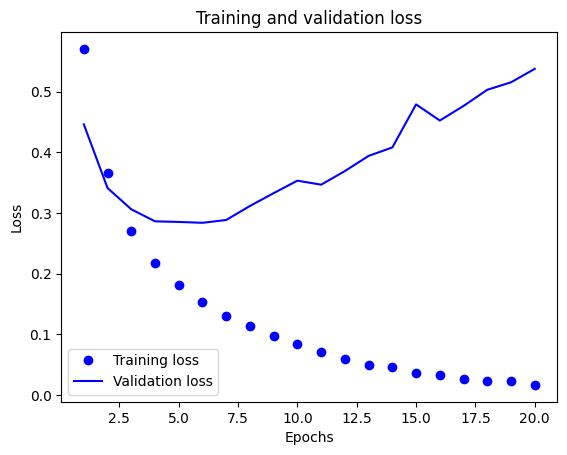

In [15]:
# Plotten van training en validation loss

history_dict = history.history
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

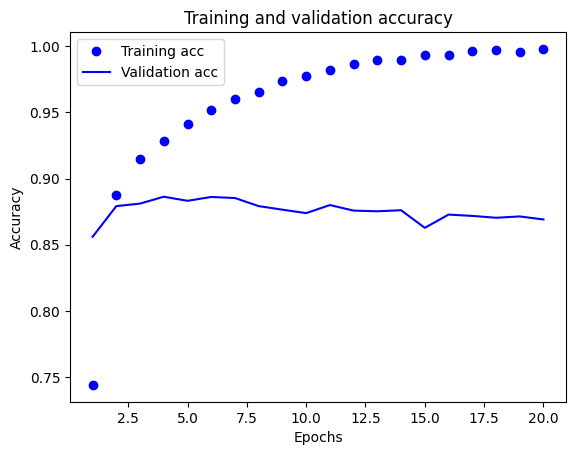

In [16]:
# Plotten van training en validation accuracy

plt.clf()  # wist voorgaande
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Zoals je kunt zien, neemt het training loss af met elk epoch en neemt de training accuracy toe met elk epoch. Dat is wat je zou verwachten bij het uitvoeren van gradient descent optimalisatie - de hoeveelheid die je probeert te minimaliseren zou bij elke iteratie minder moeten zijn. Maar dat is niet het geval voor het validation loss en accuracy: ze lijken te pieken bij de vierde epoch. Dit is een voorbeeld van overfitting: een model dat beter presteert op de trainingsdata is niet noodzakelijk een model dat het beter zal doen op data die het nog nooit eerder heeft gezien. Na het vierde epoch ben je teveel aan het optimaliseren op de trainingsdata en eindig je met het leren van representaties die specifiek zijn voor de trainingsdata en niet generaliseren naar data buiten de trainingset.

In [17]:
x_test.shape

(25000, 10000)

In [18]:
x_test_bis = x_test[:1000]
x_test_bis.shape

(1000, 10000)

In [19]:
# Voorspellen aan de hand van het getrainde model

model.predict(x_test_bis)

32/32 [==============================] - 0s 705us/step


array([[4.49378863e-02],
       [9.99982655e-01],
       [9.50535655e-01],
       [9.73502815e-01],
       [9.90682006e-01],
       [9.95308101e-01],
       [9.99948561e-01],
       [1.23708805e-05],
       [9.88137543e-01],
       [9.99992251e-01],
       [9.93144810e-01],
       [1.46896564e-04],
       [7.35226990e-10],
       [2.71032355e-03],
       [9.99536276e-01],
       [9.40367711e-14],
       [8.26526523e-01],
       [5.80488622e-01],
       [5.75672630e-06],
       [4.07405343e-04],
       [9.99951601e-01],
       [9.99591708e-01],
       [9.41289216e-03],
       [9.95173097e-01],
       [9.15562689e-01],
       [9.99965608e-01],
       [5.36159128e-02],
       [9.85070169e-01],
       [9.99951839e-01],
       [1.69702932e-11],
       [9.99210119e-01],
       [4.48889397e-02],
       [9.89688814e-01],
       [2.32385480e-15],
       [3.91871945e-05],
       [1.26722441e-07],
       [9.99951303e-01],
       [9.99351501e-01],
       [3.66079174e-02],
       [3.83538136e-05],


In [20]:
y_test[2]

1.0

In [21]:
len(y_test)

25000

Voor sommige voorspellingen is het model vrij zeker, voor andere minder...

# Multiclass Classification

## Reuters Dataset

In de vorige sectie zagen we hoe je een vector input kunt classificeren in twee onderling exclusieve klassen met behulp van een dense neuraal netwerk. Maar wat gebeurt er als je meer dan twee klassen hebt?
In deze sectie gaan we een model bouwen om Reuters nieuwsberichten te classificeren in 46 onderling exclusieve onderwerpen. Omdat we veel klassen hebben, is dit probleem een voorbeeld van multiclass classificatie, en omdat elk datapunt slechts in één categorie moet worden geclassificeerd, is het probleem meer specifiek een voorbeeld van single-label multiclass classificatie. Als elk datapunt tot meerdere categorieën zou kunnen behoren (in dit geval onderwerpen), zouden we te maken hebben met een multilabel multiclass classificatieprobleem.

**De Reuters dataset**
We gaan werken met de Reuters dataset, een verzameling van korte nieuwsberichten en hun onderwerpen, gepubliceerd door Reuters in 1986. Het is een eenvoudige, veelgebruikte dataset voor tekstclassificatie. Er zijn 46 verschillende onderwerpen; sommige onderwerpen zijn meer vertegenwoordigd dan andere, maar elk onderwerp heeft minstens 10 voorbeelden in de trainingsset.
Net als IMDB en MNIST, wordt de Reuters dataset meegeleverd als onderdeel van Keras. Laten we eens kijken.

In [22]:
from tensorflow.keras.datasets import reuters
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(
    num_words=10000)

2110848/2110848 [==============================] - 1s 0us/step


In [23]:
print(len(train_data))
print(len(test_data))
print(train_data[10])

8982
2246
[1, 245, 273, 207, 156, 53, 74, 160, 26, 14, 46, 296, 26, 39, 74, 2979, 3554, 14, 46, 4689, 4329, 86, 61, 3499, 4795, 14, 61, 451, 4329, 17, 12]


In [24]:
# Decoderen van een nieuwsbericht naar tekst

word_index = reuters.get_word_index()
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()])
decoded_newswire = " ".join([reverse_word_index.get(i - 3, "?") for i in
    train_data[0]])

550378/550378 [==============================] - 0s 0us/step


In [25]:
decoded_newswire

'? ? ? said as a result of its december acquisition of space co it expects earnings per share in 1987 of 1 15 to 1 30 dlrs per share up from 70 cts in 1986 the company said pretax net should rise to nine to 10 mln dlrs from six mln dlrs in 1986 and rental operation revenues to 19 to 22 mln dlrs from 12 5 mln dlrs it said cash flow per share this year should be 2 50 to three dlrs reuter 3'

### Voorbereiden van de data

In [26]:
x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

In [27]:
# encoderen van de labels
y_train = to_categorical(train_labels)
y_test = to_categorical(test_labels)

### Bouwen van het model

In een stack van Dense layers zoals voorheen gebruikt, kan elke laag alleen toegang krijgen tot informatie die aanwezig is in de output van de vorige laag. Als een laag enige informatie verliest die relevant is voor het classificatieprobleem, kan deze informatie nooit worden hersteld door latere lagen: elke laag kan potentieel een "informatie bottleneck" worden. In het vorige voorbeeld gebruikten we 16-dimensionale tussenliggende lagen, maar een 16-dimensionale ruimte kan te beperkt zijn om te leren 46 verschillende klassen te scheiden.
Om deze reden zullen we grotere lagen gebruiken. Laten we kiezen voor 64 eenheden.

In [28]:
model = keras.Sequential([
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(46, activation="softmax")   # softmax ipv sigmoid!
])

### Compileren van het model

In [29]:
model.compile(optimizer="rmsprop",
              loss="categorical_crossentropy",
              metrics=["accuracy"])

### Afzonderen van een validatie set

In [30]:
x_val = x_train[:1000]
partial_x_train = x_train[1000:]
y_val = y_train[:1000]
partial_y_train = y_train[1000:]

### Trainen van het model

In [31]:
history = model.fit(partial_x_train,
                    partial_y_train,
                    epochs=20,
                    batch_size=512,
                    validation_data=(x_val, y_val))

Epoch 1/20
16/16 [==============================] - 1s 20ms/step - loss: 2.8048 - accuracy: 0.4957 - val_loss: 1.8838 - val_accuracy: 0.6140
Epoch 2/20
16/16 [==============================] - 0s 12ms/step - loss: 1.5445 - accuracy: 0.6848 - val_loss: 1.3846 - val_accuracy: 0.7000
Epoch 3/20
16/16 [==============================] - 0s 13ms/step - loss: 1.1736 - accuracy: 0.7432 - val_loss: 1.2053 - val_accuracy: 0.7250
Epoch 4/20
16/16 [==============================] - 0s 12ms/step - loss: 0.9650 - accuracy: 0.7938 - val_loss: 1.0867 - val_accuracy: 0.7690
Epoch 5/20
16/16 [==============================] - 0s 12ms/step - loss: 0.8006 - accuracy: 0.8289 - val_loss: 1.0526 - val_accuracy: 0.7660
Epoch 6/20
16/16 [==============================] - 0s 13ms/step - loss: 0.6765 - accuracy: 0.8497 - val_loss: 0.9686 - val_accuracy: 0.7950
Epoch 7/20
16/16 [==============================] - 0s 12ms/step - loss: 0.5691 - accuracy: 0.8740 - val_loss: 0.9256 - val_accuracy: 0.7980
Epoch 8/20
16

### Plotten van het training en validatie loss

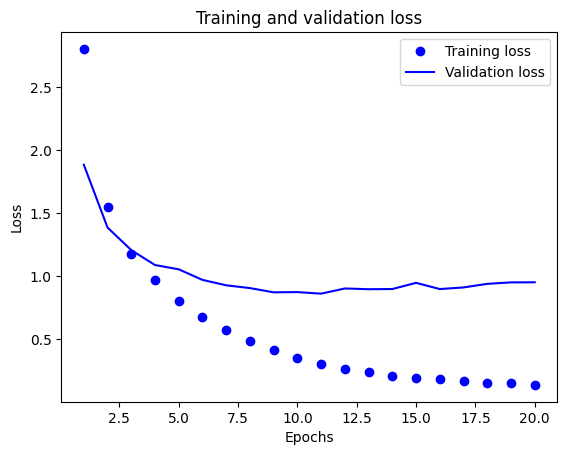

In [32]:
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Plotten van training en validatie accuracy

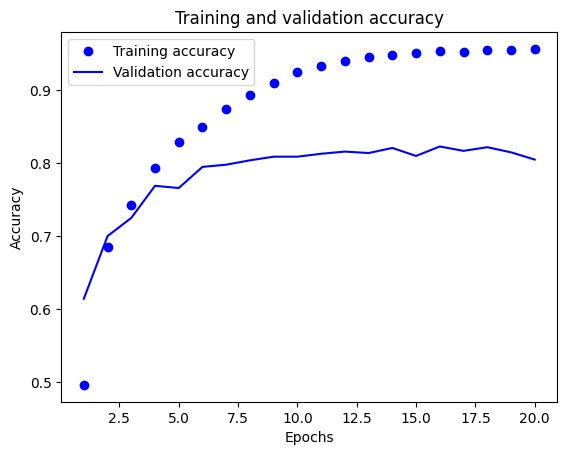

In [33]:
plt.clf()
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [34]:
# retrainen met 9 epochs
model = keras.Sequential([
  layers.Dense(64, activation="relu"),
  layers.Dense(64, activation="relu"),
  layers.Dense(46, activation="softmax")
])
model.compile(optimizer="rmsprop",
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.fit(x_train,
          y_train,
          epochs=9,
          batch_size=512)
results = model.evaluate(x_test, y_test)

Epoch 1/9
18/18 [==============================] - 1s 10ms/step - loss: 2.5606 - accuracy: 0.5218
Epoch 2/9
18/18 [==============================] - 0s 10ms/step - loss: 1.4403 - accuracy: 0.6936
Epoch 3/9
18/18 [==============================] - 0s 10ms/step - loss: 1.1169 - accuracy: 0.7515
Epoch 4/9
18/18 [==============================] - 0s 11ms/step - loss: 0.9093 - accuracy: 0.7990
Epoch 5/9
18/18 [==============================] - 0s 11ms/step - loss: 0.7525 - accuracy: 0.8376
Epoch 6/9
18/18 [==============================] - 0s 10ms/step - loss: 0.6233 - accuracy: 0.8662
Epoch 7/9
18/18 [==============================] - 0s 11ms/step - loss: 0.5191 - accuracy: 0.8925
Epoch 8/9
18/18 [==============================] - 0s 11ms/step - loss: 0.4362 - accuracy: 0.9090
Epoch 9/9
71/71 [==============================] - 0s 1ms/step - loss: 0.8974 - accuracy: 0.7898


In [35]:
results  # loss & accuracy

[0.8974444270133972, 0.7898486256599426]

In [36]:
# We bereiken ongeveer 80% accuracy.  Wat zou dit zijn bij een random classifier?

import copy
test_labels_copy = copy.copy(test_labels)
np.random.shuffle(test_labels_copy)
hits_array = np.array(test_labels) == np.array(test_labels_copy)
hits_array.mean()

0.18076580587711488

### Voorspellen op nieuwe data

In [37]:
predictions = model.predict(x_test)

71/71 [==============================] - 0s 948us/step


In [38]:
predictions[0].shape

(46,)

In [39]:
np.sum(predictions[0])

0.9999998

In [40]:
np.argmax(predictions[0])

3

### Alternatief voor de labels en loss
Je kan de labels ook op een andere manier encoderen: je kan ze naar integer tensors casten

In [41]:
model.compile(optimizer="rmsprop",
              loss="categorical_crossentropy",   
              metrics=["accuracy"])

In [42]:
print(x_train.shape)
print(y_train.shape)

(8982, 10000)
(8982, 46)


In [43]:
model.fit(x_train,
          y_train,
          epochs=9,
          batch_size=512)
results = model.evaluate(x_test, y_test)

Epoch 1/9
18/18 [==============================] - 0s 10ms/step - loss: 0.3257 - accuracy: 0.9292
Epoch 2/9
18/18 [==============================] - 0s 10ms/step - loss: 0.2681 - accuracy: 0.9393
Epoch 3/9
18/18 [==============================] - 0s 11ms/step - loss: 0.2367 - accuracy: 0.9448
Epoch 4/9
18/18 [==============================] - 0s 10ms/step - loss: 0.2098 - accuracy: 0.9499
Epoch 5/9
18/18 [==============================] - 0s 10ms/step - loss: 0.1931 - accuracy: 0.9478
Epoch 6/9
18/18 [==============================] - 0s 10ms/step - loss: 0.1753 - accuracy: 0.9527
Epoch 7/9
18/18 [==============================] - 0s 10ms/step - loss: 0.1663 - accuracy: 0.9522
Epoch 8/9
18/18 [==============================] - 0s 10ms/step - loss: 0.1534 - accuracy: 0.9554
Epoch 9/9
71/71 [==============================] - 0s 1ms/step - loss: 0.9574 - accuracy: 0.8041


# Deep learning Regressie

## De Boston Housing Price dataset

In dit deel zullen we proberen de mediaanprijs van huizen in een voorstad van Boston in het midden van de jaren 70 te voorspellen, op basis van datapunten over de voorstad op dat moment, zoals de criminaliteitsgraad, het lokale onroerend goed belastingtarief, enzovoort. De dataset die we zullen gebruiken heeft een interessant verschil met de twee vorige voorbeelden. Het heeft relatief weinig datapunten: slechts 506, verdeeld over 404 trainingssamples en 102 testsamples. En elk kenmerk in de invoerdata (bijvoorbeeld de criminaliteitsgraad) heeft een verschillende schaal. Sommige waarden zijn proporties, die waarden nemen tussen 0 en 1, andere nemen waarden aan tussen 1 en 12, weer andere tussen 0 en 100, enzovoort.

In [44]:
from tensorflow.keras.datasets import boston_housing
(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()

57026/57026 [==============================] - 0s 1us/step


In [45]:
print(train_data.shape)
print(test_data.shape)

(404, 13)
(102, 13)


### Voorbereiden van de data

#### Normaliseren

Het zou problematisch zijn om waarden die sterk uiteenlopen in bereik in een neuraal netwerk te voeren. Het model zou misschien automatisch kunnen aanpassen aan dergelijke heterogene data, maar het zou het leren zeker moeilijker maken. Een veelgebruikte best practice om met dergelijke gegevens om te gaan, is om normalisatie per kenmerk te doen: voor elk kenmerk in de invoerdata (een kolom in de invoerdatamatrix) trekken we het gemiddelde van het kenmerk af en delen we door de standaardafwijking, zodat het kenmerk rond 0 gecentreerd is en een standaardafwijking van één heeft. Dit is eenvoudig te doen in NumPy.

In [46]:
mean = train_data.mean(axis=0)
train_data -= mean
std = train_data.std(axis=0)
train_data /= std
test_data -= mean
test_data /= std

### Bouwen van het model

In [47]:
def build_model():
    model = keras.Sequential([
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
    return model

Merk op:  
-We hebben heel weinig samples.  Daarom gebruiken we een beperkt model met 2 layers met elk 64 units.  Hoe minder data je hebt, hoe gevoeliger aan overfitting!  
-één enkel neuron als output.  Dit wordt niet 'geactiveerd' omdat dit anders binnen grenzen zoals [0,1] zou worden gedwongen.  De laatste layer is omwille van het ontbreken van activatie volledig lineair, en kan dut waarden in elke range leren voorspellen.  
-Als loss function gebruiken we MSE.  Dit is veelgebruikt voor regressieproblemen.  
-We hebben een functie gemaakt voor build_model...

### Validatie via K-fold

Omwille van de kleine dataset zou de validatie set heel klein zijn.  Daarom gebruiken we K-fold cross validation.

In [48]:
k = 4
num_val_samples = len(train_data) // k
num_epochs = 100
all_scores = []
for i in range(k):
    print(f"Processing fold #{i}")
    val_data = train_data[i * num_val_samples: (i + 1) * num_val_samples]
    val_targets = train_targets[i * num_val_samples: (i + 1) * num_val_samples]
    partial_train_data = np.concatenate(
        [train_data[:i * num_val_samples],
         train_data[(i + 1) * num_val_samples:]],
        axis=0)
    partial_train_targets = np.concatenate(
        [train_targets[:i * num_val_samples],
         train_targets[(i + 1) * num_val_samples:]],
        axis=0)
    model = build_model()
    model.fit(partial_train_data, partial_train_targets,
              epochs=num_epochs, batch_size=16, verbose=0)
    val_mse, val_mae = model.evaluate(val_data, val_targets, verbose=0)
    all_scores.append(val_mae)

Processing fold #0
Processing fold #1
Processing fold #2
Processing fold #3


In [49]:
all_scores

[1.9406206607818604, 2.4064974784851074, 2.375157356262207, 2.370232105255127]

In [50]:
np.mean(all_scores)

2.2731269001960754

We hebben een gemiddelde fout van zo'n 2400€ bij een range van 10 tot 50K€.  We proberen nu eens te trainen voor 500 epochs en bewaren de per-epoch validatie score voor elke fold

In [51]:
num_epochs = 500
all_mae_histories = []
for i in range(k):
    print(f"Processing fold #{i}")
    val_data = train_data[i * num_val_samples: (i + 1) * num_val_samples]
    val_targets = train_targets[i * num_val_samples: (i + 1) * num_val_samples]
    partial_train_data = np.concatenate(
        [train_data[:i * num_val_samples],
         train_data[(i + 1) * num_val_samples:]],
        axis=0)
    partial_train_targets = np.concatenate(
        [train_targets[:i * num_val_samples],
         train_targets[(i + 1) * num_val_samples:]],
        axis=0)
    model = build_model()
    history = model.fit(partial_train_data, partial_train_targets,
                        validation_data=(val_data, val_targets),
                        epochs=num_epochs, batch_size=16, verbose=0)
    mae_history = history.history["val_mae"]
    all_mae_histories.append(mae_history)

Processing fold #0
Processing fold #1
Processing fold #2
Processing fold #3


We berekenen het gemiddelde van de per-epoch-MAE score voor alle folds:

In [52]:
average_mae_history = [np.mean([x[i] for x in all_mae_histories]) for i in range(num_epochs)]

### Plotten van de validatie scores

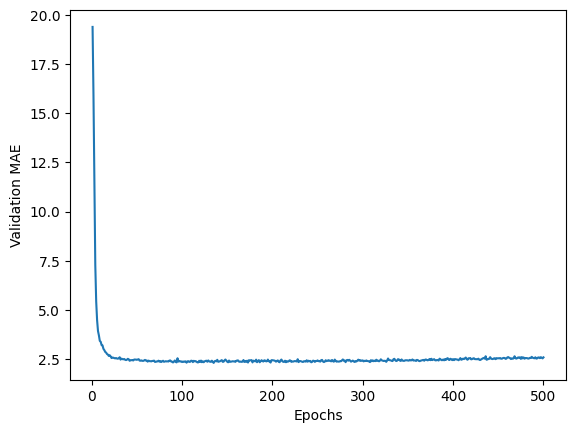

In [53]:
plt.plot(range(1, len(average_mae_history) + 1), average_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

### Plot van de validatie scores excl de eerste 10 waarden

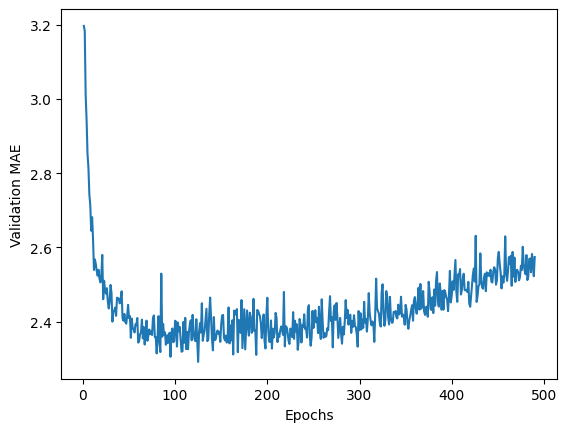

In [54]:
truncated_mae_history = average_mae_history[10:]
plt.plot(range(1, len(truncated_mae_history) + 1), truncated_mae_history)
plt.xlabel("Epochs")
plt.ylabel("Validation MAE")
plt.show()

### Trainen van het finale model

In [55]:
model = build_model()
model.fit(train_data, train_targets,
          epochs=130, batch_size=16, verbose=0)
test_mse_score, test_mae_score = model.evaluate(test_data, test_targets)

4/4 [==============================] - 0s 1ms/step - loss: 14.4867 - mae: 2.3372


In [56]:
test_mae_score

2.3372180461883545

### Voorspellen op basis van het model

In [57]:
predictions = model.predict(test_data)
predictions[0]

4/4 [==============================] - 0s 813us/step


array([7.8174596], dtype=float32)